# Medical cost regression: ordinary least squares and SGD

Linear regression and SGD applied to the medical cost dataset.

Saved outputs are from the original coursework run, before the small fixes in this copy. The notebooks have not been rerun.


MEAN_CHARGE 13270.422265141257
MEDIAN_CHARGE 9382.033
index fof the values > 30000 (WildPoints):  162 1176
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
NEW_MEAN_CHARGE 9483.412418681122
NEW_MEDIAN_CHARGE 8246.43695
RMSE for Multiple Linear Regression: 3573.5621122493963
R-squared: 0.6608956078171484
RMSE for SGD Regressor: 3574.822674163905
R-squared: 0.660656329773953

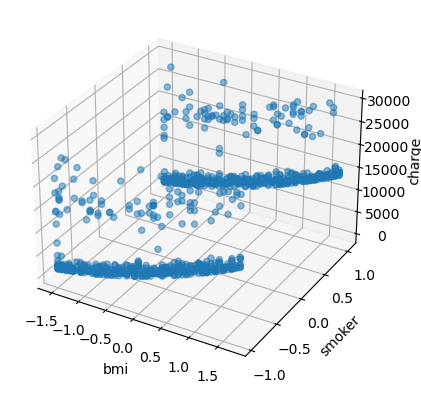

In [ ]:
#Import needed packages
import numpy as np
import gc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import pandas as pd
import warnings
warnings.filterwarnings('ignore', module='sklearn')
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error 
from math import sqrt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import statsmodels.api as sm
from sklearn.metrics import r2_score




# Load the dataset
file_path = "data/Medical Cost Personal Dataset.csv"
df = pd.read_csv(file_path)

print("MEAN_CHARGE",  df['charges'].mean())
print("MEDIAN_CHARGE", df["charges"].median())
index = 0    
#drop outliers, the wild points over 30000 charges(those points are 12% of the total points)
for i in range(0, len(df.smoker)):
    if df.charges[i] > 30000:
        index= index + 1
        df.drop(i, inplace = True)

        
print("index fof the values > 30000 (WildPoints): "  ,index, len(df.smoker))
df.reset_index(drop=True, inplace=True)

print(df.head(5))
#convert everything to numerical
#sex to binary
for i in range(len(df.sex)):
    if df.sex[i] == "male":
        df.loc[i, "sex"] = 1
    else:
        df.loc[i, "sex"] = 0
        
# Convert the column to integer type
df["sex"] = df["sex"].astype(int)
        
#smoke to binary
for i in range(len(df.smoker)):
    if df.smoker[i] == "yes":
        df.loc[i, "smoker"] = 1
    else:
        df.loc[i, "smoker"] = 0
        
# Convert the column to integer type
df["smoker"] = df["smoker"].astype(int)

for i in range(len(df.region)):
    if df.region[i] == "southwest":
        df.loc[i, "region"] = 0
    elif df.region[i] == "southeast":
        df.loc[i, "region"] = 2
    elif df.region[i] == "northwest":
        df.loc[i, "region"] = 3
    elif df.region[i] == "northeast":
        df.loc[i, "region"] = 1
        
df["region"] = df["region"].astype(int)
#southwest = 1
#southeast = 2
#northwest = 3
#northeast = 4

print("NEW_MEAN_CHARGE",  df['charges'].mean())
print("NEW_MEDIAN_CHARGE", df["charges"].median())

# Define the features and target variable
# Assuming 'Sales' is the target and all other columns are features
X = df.drop('charges', axis=1)
y = df['charges']


# Split the dataset into training and testing sets
random_seed = 42  # Using a fixed random seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_seed, test_size=0.20)
#print("Y_TEST\n",y_test)

# Create and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Predicting the Test set results
y_pred = lin_reg.predict(X_test)

# Calculate RMSE for the model
rmse = sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE for Multiple Linear Regression: {rmse}')
# Calculate R-squared
r_squared = r2_score(y_test, y_pred)
print("R-squared:", r_squared)




# Standardizing the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#X_train_scaled = X_train
#X_test_scaled = X_test
# Create and train the SGD Regressor model
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, random_state=random_seed)
sgd_reg.fit(X_train_scaled, y_train)

# Predicting the Test set results
y_pred = sgd_reg.predict(X_test_scaled)

# Calculate RMSE for the model
rmse = sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE for SGD Regressor: {rmse}')

# Calculate R-squared
r_squared = r2_score(y_test, y_pred)
print("R-squared:", r_squared)


# Prepare the figure for animation in 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
line, = ax.plot([], [], [], 'r-', linewidth=2)
ax.scatter(X_train_scaled[:,2], X_train_scaled[:,4], y_train, alpha=0.5)  # Plot the data points
ax.set_xlabel('bmi')
ax.set_ylabel('smoker')
ax.set_zlabel('charge')


# Function to initialize the animation
def init():
    line.set_data([], [])
    line.set_3d_properties([])
    return line,

# Function to update the animation
def update(frame):
    sgd_reg.fit(X_train_scaled, y_train) 
    coef = sgd_reg.coef_
    intercept = sgd_reg.intercept_
    x = np.linspace(X_train_scaled[:,2].min(), X_train_scaled[:,2].max(), 100)
    y = np.linspace(X_train_scaled[:,4].min(), X_train_scaled[:,4].max(), 100)
    x, y = np.meshgrid(x, y)
    z = intercept + coef[2] * x + coef[4] * y
    line.set_data(x.flatten(), y.flatten())
    line.set_3d_properties(z.flatten())
    return line,

# Create the animation
ani = FuncAnimation(fig, update, frames=np.arange(100), init_func=init, blit=False)

# To display the animation in Jupyter Notebook
HTML(ani.to_jshtml())


# Comments:

We decided to drop the wildpoints (values bigger than 30000) for the data set to be better fitted with a linear function. The value 30000 was decided with the aim to reduse the mean value of the charge without reducing a lot the median value. After manipulating the data set with encoding of the features to be numerical we applied Multiple Linear Regression and SGD Regressor. The results of both were extremely similar . For the metrics of RMSE and R-squared which we used we observed that the RMSE of 3573 is a really good one while the 0.66 of the R-squared not that much and that the behaved in an inverse way when manipulating the outliers differently . At first that seemed really strange but given that the RMSE evaluates the prediction accuracy of the fit while the R-squared the variability that the independent variables capture it is a possible scenario (probably because of the change of mean value which is used in R-squared)